# Исследование моделей отмены бронирований

Продолжение разведочного анализа. Сначала сравниваю модели и подбираю параметры в ноутбуке, затем переношу победителя в отдельный скрипт для финального обучения.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os


from sklearn.preprocessing import (
    OrdinalEncoder,
    OneHotEncoder
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import (
    Pipeline,
    make_pipeline
)
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import (
    LinearSVC,
    SVC
)
from sklearn.neighbors import KNeighborsClassifier


from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, precision_recall_curve)
from sklearn.base import clone
from IPython.display import display

SEED = 42
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = PROJECT_DIR / 'data' / 'raw' / 'hotel_bookings.csv'
LEAKAGE_COLS = ['reservation_status', 'reservation_status_date', 'assigned_room_type',
                'booking_changes', 'days_in_waiting_list']
def load_data():
    df = pd.read_csv(DATA_PATH)
    df = df.drop_duplicates().reset_index(drop=True)
    df = df.drop(columns=LEAKAGE_COLS)
    df = df.replace('Undefined', np.nan)
    df['children'] = pd.to_numeric(df['children'], errors='coerce')

    # ID агентства и компании являются категориями, а не порядковыми числами.
    for col in ['agent', 'company']:
        df[col] = df[col].astype('string').fillna('missing')

    y = df.pop('is_canceled').astype(int)
    return df, y

def make_pipeline(model, X):
    categorical = X.select_dtypes(include=['object', 'string']).columns.tolist()
    numeric = X.columns.difference(categorical).tolist()

    numeric_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore',
                                  min_frequency=50, sparse_output=True))
    ])
    preprocessing = ColumnTransformer([
        ('numeric', numeric_pipe, numeric),
        ('categorical', categorical_pipe, categorical)
    ])
    return Pipeline([('preprocessing', preprocessing), ('model', model)])

def models_and_params():
    return {
        'LogisticRegression': (LogisticRegression(max_iter=700, random_state=SEED),
                               {'model__C': [0.1, 1.0, 10.0]}),
        'SVM': (SVC(probability=True, random_state=SEED),
                {'model__C': [0.3, 1.0], 'model__gamma': ['scale']}),
        'KNN': (KNeighborsClassifier(),
                {'model__n_neighbors': [15, 31], 'model__weights': ['uniform', 'distance']}),
        'MLP': (MLPClassifier(max_iter=120, early_stopping=True, random_state=SEED),
                {'model__hidden_layer_sizes': [(32,), (64,)], 'model__alpha': [0.001]}),
        'RandomForest': (RandomForestClassifier(n_estimators=120, n_jobs=1,
                                                 random_state=SEED),
                         {'model__max_depth': [12, 20], 'model__min_samples_leaf': [2]}),
        'CatBoost': (CatBoostClassifier(iterations=180, verbose=False,
                                        thread_count=4, random_seed=SEED),
                     {'model__depth': [4, 6], 'model__learning_rate': [0.05]}),
        'LightGBM': (LGBMClassifier(n_estimators=180, verbosity=-1,
                                    n_jobs=4, random_state=SEED),
                     {'model__num_leaves': [15, 31], 'model__learning_rate': [0.05]}),
        'AdaBoost': (AdaBoostClassifier(n_estimators=120, random_state=SEED),
                     {'model__learning_rate': [0.3, 1.0]})
    }

def get_metrics(y_true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {
        'accuracy': accuracy_score(y_true, predicted),
        'precision': precision_score(y_true, predicted, zero_division=0),
        'recall': recall_score(y_true, predicted, zero_division=0),
        'f1': f1_score(y_true, predicted, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probability),
        'pr_auc': average_precision_score(y_true, probability)
    }

def loss_table(y_true, probability, cost_fn=200, cost_fp=20):
    """Учебный сценарий: пропущенная отмена дороже ложной тревоги."""
    rows = []
    for threshold in np.arange(0.1, 0.91, 0.05):
        predicted = probability >= threshold
        fn = int(((y_true == 1) & ~predicted).sum())
        fp = int(((y_true == 0) & predicted).sum())
        rows.append({'threshold': round(float(threshold), 2), 'fn': fn,
                     'fp': fp, 'assumed_loss': fn * cost_fn + fp * cost_fp})
    return pd.DataFrame(rows)

## Данные и схема проверки

Удаляю точные дубли до разделения. Исключаю признаки, появляющиеся после оформления брони. Преобразования категорий и чисел обучаются внутри каждого фолда через Pipeline. Тестовые 20% не участвуют в подборе модели.

In [3]:
raw = pd.read_csv(DATA_PATH)
print('Строк:', len(raw), 'точных дублей:', raw.duplicated().sum())
X, y = load_data()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
    stratify=y, random_state=SEED)
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=8000,
    stratify=y_train, random_state=SEED)
print('Train:', len(X_train), 'test:', len(X_test), 'доля отмен:', round(y.mean(), 3))

## Метрики

Accuracy — доля верных ответов, Precision — доля настоящих отмен среди предсказанных, Recall — доля найденных отмен, F1 объединяет Precision и Recall. ROC-AUC оценивает ранжирование по всем порогам. Для PR-кривой использую Average Precision (AP): она показывает, как растёт число ложных тревог при повышении Recall.

In [4]:
results = []
fold_results = []
test_probabilities = {}
best_models = {}

def compare_model(name):
    model, params = models_and_params()[name]
    for cv_name, cv in [('KFold', KFold(n_splits=3, shuffle=True, random_state=SEED)),
                        ('StratifiedKFold', StratifiedKFold(n_splits=3, shuffle=True,
                                                           random_state=SEED))]:
        search = RandomizedSearchCV(make_pipeline(model, X_small), params,
            n_iter=2, scoring='roc_auc', cv=cv, random_state=SEED,
            n_jobs=1, refit=True, return_train_score=True)
        search.fit(X_small, y_small)
        i = search.best_index_
        for fold in range(3):
            fold_results.append({'model': name, 'cv': cv_name, 'fold': fold+1,
                'train_roc_auc': search.cv_results_[f'split{fold}_train_score'][i],
                'validation_roc_auc': search.cv_results_[f'split{fold}_test_score'][i]})
        if cv_name == 'StratifiedKFold':
            p = search.predict_proba(X_test)[:, 1]
            test_probabilities[name] = p
            best_models[name] = search.best_estimator_
            results.append({'model': name, 'cv_roc_auc': search.best_score_,
                **get_metrics(y_test, p)})
    return pd.DataFrame(results).tail(1).round(3)

### LogisticRegression

Логистическая регрессия вычисляет $z=b+\sum w_jx_j$, затем
$p=1/(1+e^{-z})$. Вес показывает направление влияния признака при остальных
равных. Плюс — простота и интерпретируемость; минус — линейная граница без
дополнительных нелинейных признаков.

In [5]:
compare_model('LogisticRegression')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
LogisticRegression,0.8473,0.7935,0.6710,0.4880,0.5651,0.8464,0.6664


### SVM

SVM выбирает границу с большим зазором между классами. Штраф $C$
регулирует цену ошибок на обучении: слишком большое значение может подогнать
границу к шуму. RBF-ядро учитывает нелинейные отношения. За это приходится
платить временем обучения.

In [6]:
compare_model('SVM')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
SVM,0.8587,0.8169,0.7182,0.5496,0.6227,0.8630,0.7176


### KNN

KNN не строит явное уравнение: вероятность оценивается по классам
ближайших соседей. При малом $k$ прогноз чувствителен к шуму, при большом —
сглаживается. Здесь особенно важны масштабирование и способ кодирования
категорий.

In [7]:
compare_model('KNN')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
KNN,0.8160,0.7900,0.6777,0.4504,0.5411,0.8243,0.6409


### MLP

Нейрон слоя вычисляет $a=\sigma(Wx+b)$; несколько слоёв позволяют
описать сложную зависимость. Оптимизация весов идёт по градиенту функции
ошибки. Сеть гибкая, но результат зависит от архитектуры и остановки обучения.

In [8]:
compare_model('MLP')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
MLP,0.8693,0.8061,0.6978,0.5195,0.5956,0.8632,0.7049


### RandomForest

Лес усредняет прогнозы многих деревьев, обученных на
разных подвыборках. Отдельное дерево легко переобучается; усреднение снижает
разброс. Глубина и минимальный размер листа ограничивают сложность.

In [9]:
compare_model('RandomForest')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
RandomForest,0.8793,0.8240,0.7606,0.5251,0.6213,0.8885,0.7527


### CatBoost

Бустинг добавляет деревья последовательно, уменьшая ошибку
текущего ансамбля. Скорость обучения определяет размер каждого шага.
CatBoost умеет работать с категориями сам, но в этом сравнении все модели
получают одинаковое кодирование, поэтому это преимущество не проверяется.

In [10]:
compare_model('CatBoost')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
CatBoost,0.8897,0.8306,0.7463,0.5815,0.6536,0.8914,0.7586


### LightGBM

LightGBM тоже строит сумму деревьев. В отличие от леса,
новое дерево исправляет ошибки уже построенных. Число листьев задаёт гибкость:
больше листьев может улучшить train и ухудшить validation.

In [11]:
compare_model('LightGBM')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
LightGBM,0.8908,0.8313,0.7327,0.6081,0.6646,0.8947,0.7624


### AdaBoost

AdaBoost повышает вес наблюдений, на которых предыдущие
слабые модели ошибались. Итоговый ответ — взвешенное голосование. Метод
прост, но может уделять слишком много внимания шумным примерам.

In [12]:
compare_model('AdaBoost')

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
AdaBoost,0.8556,0.8014,0.6991,0.4870,0.5741,0.8553,0.6817


## Сравнение моделей, KFold и StratifiedKFold

Среднее и разброс по трём фолдам показывают устойчивость. Выбираю модель по среднему ROC-AUC StratifiedKFold; тест использую только для итоговой оценки.

model,cv_roc_auc,accuracy,precision,recall,f1,roc_auc,pr_auc
LightGBM,0.8908,0.8313,0.7327,0.6081,0.6646,0.8947,0.7624
CatBoost,0.8897,0.8306,0.7463,0.5815,0.6536,0.8914,0.7586
RandomForest,0.8793,0.8240,0.7606,0.5251,0.6213,0.8885,0.7527
MLP,0.8693,0.8061,0.6978,0.5195,0.5956,0.8632,0.7049
SVM,0.8587,0.8169,0.7182,0.5496,0.6227,0.8630,0.7176
AdaBoost,0.8556,0.8014,0.6991,0.4870,0.5741,0.8553,0.6817
LogisticRegression,0.8473,0.7935,0.6710,0.4880,0.5651,0.8464,0.6664
KNN,0.8160,0.7900,0.6777,0.4504,0.5411,0.8243,0.6409


index,model,cv,mean,std
0,AdaBoost,KFold,0.8572,0.0094
1,AdaBoost,StratifiedKFold,0.8556,0.0032
2,CatBoost,KFold,0.8877,0.0051
3,CatBoost,StratifiedKFold,0.8897,0.0051
4,KNN,KFold,0.8194,0.0071
5,KNN,StratifiedKFold,0.8160,0.0050
6,LightGBM,KFold,0.8918,0.0059
7,LightGBM,StratifiedKFold,0.8908,0.0021
8,LogisticRegression,KFold,0.8454,0.0084
9,LogisticRegression,StratifiedKFold,0.8473,0.0012


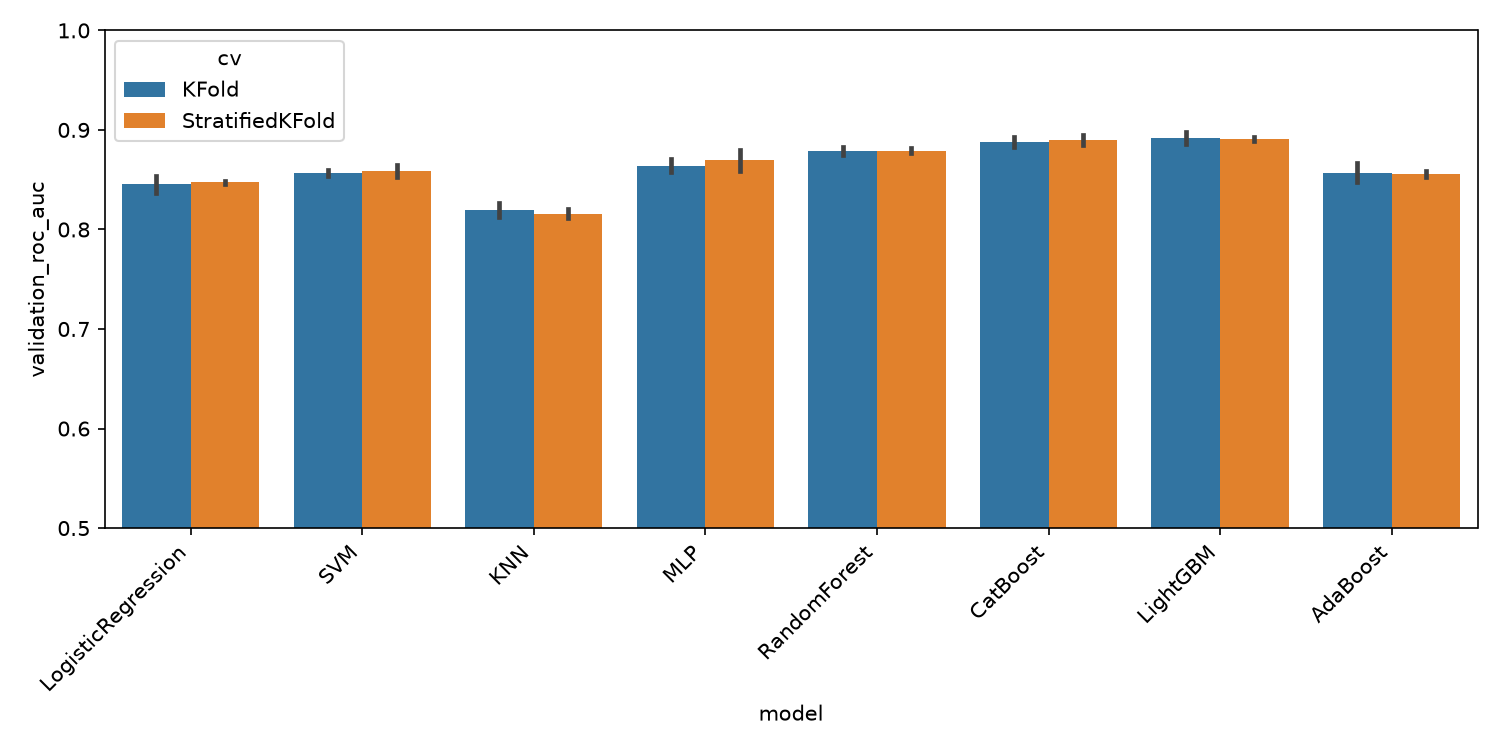

In [13]:
results_df = pd.DataFrame(results).sort_values('cv_roc_auc', ascending=False)
folds_df = pd.DataFrame(fold_results)
display(results_df.round(3))
display(folds_df.groupby(['model','cv'])['validation_roc_auc'].agg(['mean','std']).round(4))
fig, ax = plt.subplots(figsize=(10,5))
sns.barplot(data=folds_df, x='model', y='validation_roc_auc', hue='cv', errorbar='sd', ax=ax)
plt.xticks(rotation=45, ha='right'); plt.ylim(0.5,1); plt.tight_layout()
REPORT_DIR = PROJECT_DIR / 'reports'
FIGURE_DIR = REPORT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
results_df.to_csv(REPORT_DIR / 'model_comparison.csv', index=False)
folds_df.to_csv(REPORT_DIR / 'cv_folds.csv', index=False)
fig.savefig(FIGURE_DIR / 'cv_comparison.png', dpi=150)


## Переобучение

Большой разрыв между ROC-AUC на train и validation указывает на риск запоминания данных. По одному разбиению нельзя делать окончательный вывод.

In [14]:
gap = folds_df.groupby('model')[['train_roc_auc','validation_roc_auc']].mean()
gap['gap'] = gap.train_roc_auc - gap.validation_roc_auc
display(gap.sort_values('gap', ascending=False).round(3))
gap[['train_roc_auc','validation_roc_auc']].plot.barh(figsize=(9,5))
plt.xlim(0.5,1); plt.tight_layout()

model,train_roc_auc,validation_roc_auc,gap
KNN,1.0000,0.8177,0.1823
RandomForest,0.9864,0.8790,0.1075
LightGBM,0.9585,0.8913,0.0672
SVM,0.9064,0.8578,0.0486
CatBoost,0.9293,0.8887,0.0406
MLP,0.8967,0.8668,0.0299
LogisticRegression,0.8569,0.8463,0.0106
AdaBoost,0.8637,0.8564,0.0073


## PR-кривые и Recall

Recall около 0,6 при пороге 0,5 означает, что модель находит около 60% отмен. Это не случайное угадывание: нужно одновременно смотреть Precision и PR-AUC. Уменьшение порога повышает Recall ценой ложных тревог.

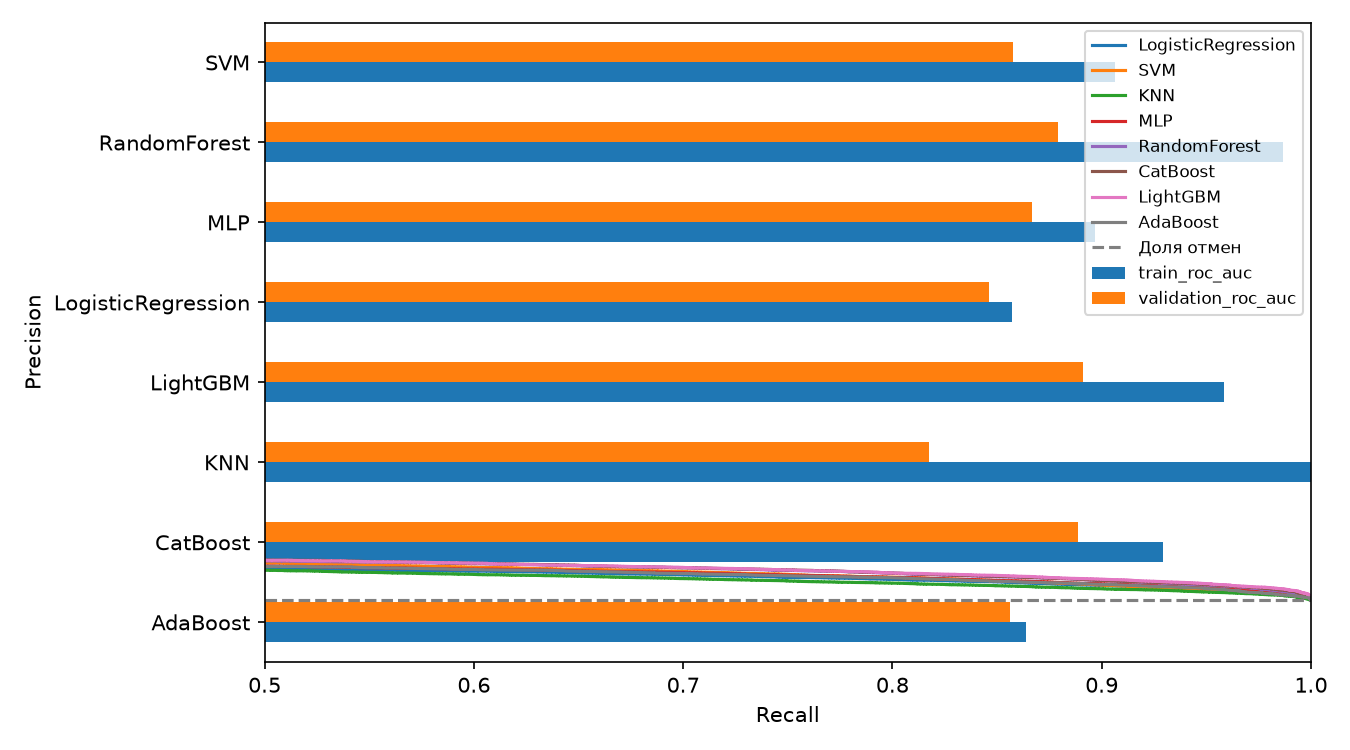

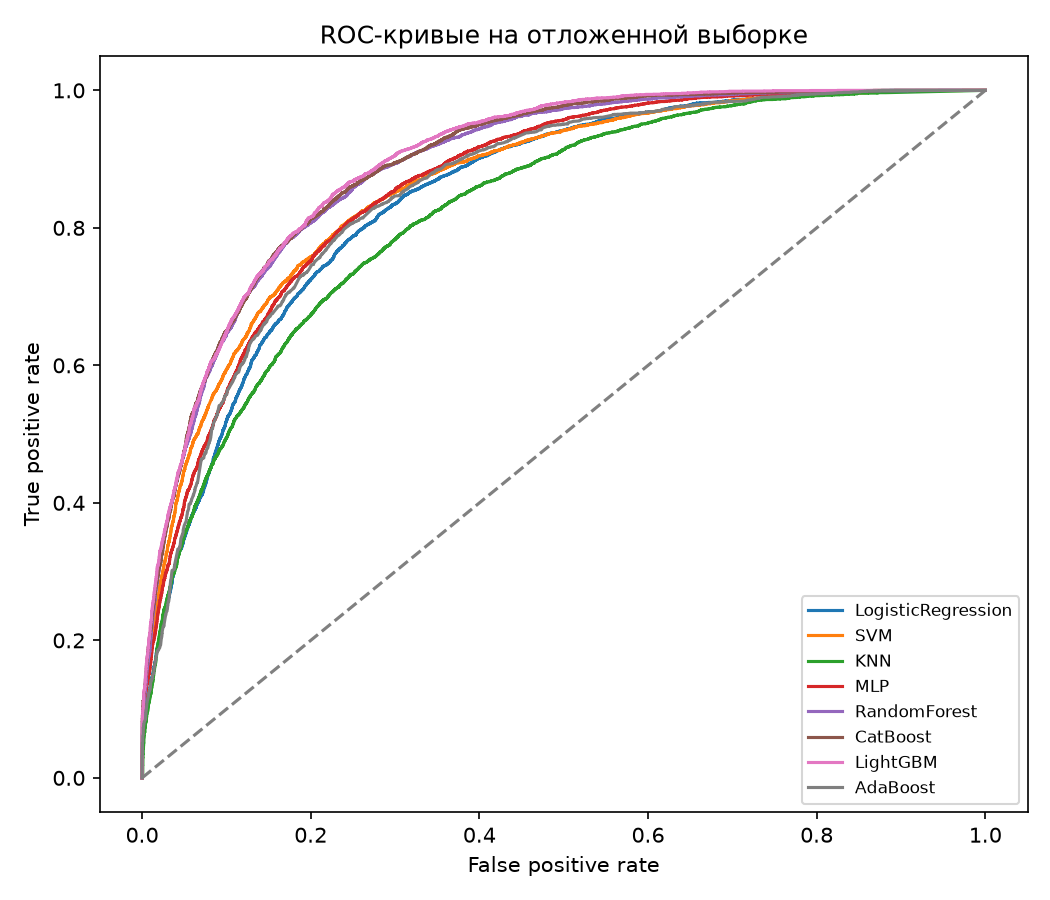

In [15]:
for name,p in test_probabilities.items():
    precision,recall,_ = precision_recall_curve(y_test,p)
    plt.plot(recall,precision,label=name)
plt.axhline(y_test.mean(),color='gray',linestyle='--',label='Доля отмен')
plt.xlabel('Recall');plt.ylabel('Precision');plt.legend(fontsize=8);plt.tight_layout()
plt.savefig(FIGURE_DIR / 'pr_curves.png', dpi=150)

plt.figure(figsize=(7, 6))
for name, p in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'roc_curves.png', dpi=150)


## Порог и цена ошибок

В учебном сценарии FN стоит 200, FP — 20 условных единиц. Подбираю порог на отдельной части train, затем фиксирую его и оцениваю на test. Это не реальные финансовые оценки отеля.

In [16]:
best_name = results_df.iloc[0]['model']
X_fit,X_valid,y_fit,y_valid = train_test_split(X_train,y_train,test_size=0.2,
    stratify=y_train,random_state=SEED)
chosen = clone(best_models[best_name])
chosen.fit(X_fit,y_fit)
valid_p = chosen.predict_proba(X_valid)[:,1]
costs = loss_table(y_valid.to_numpy(),valid_p)
threshold = float(costs.loc[costs.assumed_loss.idxmin(),'threshold'])
f1_values = [f1_score(y_valid, valid_p >= t) for t in costs.threshold]
f1_threshold = float(costs.threshold.iloc[np.argmax(f1_values)])
display(costs.sort_values('assumed_loss').head())
print('Модель:',best_name,'порог:',threshold)

threshold,fn,fp,assumed_loss,f1
0.1000,81,4556,107320,0.6188
0.1500,183,3723,111060,0.6521
0.2000,284,3104,118880,0.6776
0.2500,436,2528,137760,0.6969
0.3000,609,1988,161560,0.7136


In [17]:
chosen.fit(X_train,y_train)
final_p = chosen.predict_proba(X_test)[:,1]
for t in [0.5, f1_threshold, threshold]:
    pred = final_p >= t
    tn,fp,fn,tp = confusion_matrix(y_test,pred).ravel()
    print('Порог',t,'Accuracy',round(accuracy_score(y_test,pred),3),
          'Precision',round(precision_score(y_test,pred),3),
          'Recall',round(recall_score(y_test,pred),3),
          'F1',round(f1_score(y_test,pred),3),'FN',fn,'FP',fp,
          'потери',fn*200+fp*20)
print('ROC-AUC',round(roc_auc_score(y_test,final_p),3),
      'PR-AUC/AP',round(average_precision_score(y_test,final_p),3))

default: accuracy=0.838, precision=0.738, recall=0.637, f1=0.684, ROC-AUC=0.904, PR-AUC/AP=0.784, FN=1744, FP=1084, loss=370480
cost threshold: accuracy=0.666, precision=0.450, recall=0.976, f1=0.616, ROC-AUC=0.904, PR-AUC/AP=0.784, FN=113, FP=5728, loss=137160
F1 threshold: accuracy=0.823, precision=0.647, recall=0.788, f1=0.710, ROC-AUC=0.904, PR-AUC/AP=0.784, FN=1018, FP=2070, loss=245000


## Вывод

Понижение порога улучшает Recall, но увеличивает ложные тревоги. Важно оценивать стоимость обеих ошибок, а не выбирать модель только по Accuracy. Подробные ограничения и фактические выводы — в `reports/conclusions.md`. Итоговое обучение выбранной модели вынесено в скрипт.